<a href="https://colab.research.google.com/github/fluids/AI4GSD/blob/main/Demo_Colab/Demo1_Drone_Videos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI4GSD Demo
------------------------------------------
## Drone Videos
------------------------------------------
#### Table of contents
#### 0. Installing requried packages
#### 1. Importing required packages
#### 2. Defining working directory
#### 3. Extracting or copying your videos/photos to desired folder
#### 4. Obtaining scales from AI, drone flight data, or manual measurements
#### 5. Obtaining segmentation of anthropogenic objects
#### 6. Obtaining grain size data
#### 7. Applying quality control
#### 8. Data visualization

##### *** Please contact Yunxiang Chen, yunxiang.chen@pnnl.gov for reporting errors

------------------------------------------
### 0. Installing requried packages

#### 0a. Install requried packages

In [22]:
%pip install -q ultralytics==8.3.186 natsort pyproj PyExifTool piexif imutils shapely psutil gdown

#### 0b. Connect Google drive to Colab runtime.

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### 0c. Create AI4GSD parent direcotry and download source codes if not found.

In [24]:
import sys, subprocess
from pathlib import Path
WorkDir = Path("/content/drive/MyDrive/AI4GSD")
sys.path.insert(0,str(WorkDir))
if not WorkDir.exists():subprocess.run(["git", "clone", "--progress","https://github.com/pnnl/AI4GSD.git", str(WorkDir)],check=True)

### 1. Importing required packages

In [25]:
import AI4GSD, gdown

### 2. Defining working directory

In [26]:
AI4GSD.pcinfo()
foldername = '20241130_YC_DroneVideoFieldTest'                             # Parent folder where you save photos/videos.
PhotoDir = str(WorkDir / 'Demo_Data' / foldername)                         # AI4GSD use string path.

Machine name: b0274aed688a
Operating system: Ubuntu 24.04.5 LTS
Architecture: x86_64
Processor: Intel(R) Xeon(R) CPU @ 2.20GHz
Reported CPU frequency: 2.20 GHz
PyTorch version: 2.14.1+cpu
CUDA available: False
CUDA GPU unavailable to PyTorch


### 3. Extracting or copying your videos/photos to desired folder

#### 3a. Downloading large video file seperately because git clone may ignore it.

In [27]:
videoname = "DJI_0113.MOV"
video = Path(PhotoDir) / "videos" / videoname
if not video.exists(): gdown.download(id="1lKqpHzH5oo1CE3IY-C3au2JKrfx4QaBg",output=str(video),quiet=False,)

#### 3b. Extracting frames from videos.

In [28]:
AI4GSD.getPhotos(PhotoDir,nframe=2000, overwrite=False)                    # Use once.

Video photo output folder: /content/drive/MyDrive/AI4GSD/Demo_Data/20241130_YC_DroneVideoFieldTest
Extracting DJI_0113.MOV every 2000 frames.
DJI_0113.MOV: get frame 1 from 2000/5759 in 0.00 s (34.73%), file existed, skipping...
DJI_0113.MOV: get frame 2 from 4000/5759 in 0.00 s (69.46%), file existed, skipping...

Computation done, elapsed time 0.02 seconds.




### 4. Obtaining scales from AI, drone flight data, or manual measurements

In [29]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.OverWriteAll = True                                                     # Overwrite everything if True.
PP.OverWriteScaleFile = True
PP.OverWriteScaleRows = True
PP.ScaleSource = 'log'                                                     # Use drone log option.
PP.ModelName = 'YOLO11m.1280.20250825'                                     # Which AI to use.
PP.ComputingSource = 'local'                                               # What computing resource to use.
PP.ImageSizeFactor = 1                                                     # Do you need to user a larger image size for inference?
PP.ConfidenceThresholdUser = 0.85                                          # Minimum confidence threshold.
PP.YOLOSave = False                                                        # Need to save AI prediction to folder.
scales =  AI4GSD.metadata(PP)

Generating scale file for: 20241130_YC_DroneVideoFieldTest
Reading DJI flight logs from files
1/2: photo 1/2, DJI_0113_2000.png, scale log, res 0.59 mm/px, status -1, (50.00%), 1.80 s
2/2: photo 2/2, DJI_0113_4000.png, scale log, res 0.73 mm/px, status -1, (100.00%), 2.14 s
Total time: 4.06 s, time per photo 2.03 s
-----------------------------------------------------------------



### 5. Obtaining segmentation of anthropogenic objects

In [30]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.FolderLevel = 'L1'
PP.ModelName = 'YOLO11m.640.20250906'
PP.ObjectName = 'anthro'
PP.OverWriteSegementation = True
PP.YOLOSave = False
PP.YOLOIOU = 0.45
PP.ComputingSource = 'local'
PP.ImageSizeType = 'default'
PP.ImageSizeFactor=1
PP.SegmentationClassName = ['board','redbag','people']                     # What object class need to track.
AI4GSD.background(PP)

-----------------------------------------------------------------
Folder name: 20241130_YC_DroneVideoFieldTest
output name: segments
Model name: YOLO11m.640.20250906 from local for anthro
Model layer: 125, model parmeter: 22.37M, submodule number: 445
IOU: 0.45, user confidence: 0.35
Number of photos: 2, number of exluded photos 0
20241130_YC_DroneVideoFieldTest: 1/2, DJI_0113_2000.png, no objects (50.00%)
20241130_YC_DroneVideoFieldTest: 2/2, DJI_0113_4000.png, no objects (100.00%)
Total time: 6.49 s, time per photo 3.24 s
-----------------------------------------------------------------



### 6. Obtaining grain size data

AI4GSD: an AI and cloud powered tool for grain size quantification
AI models in use: YOLO11m.1280.20250322
Confidence thresholds in use: 0.35

-----------------------------------------------------------------
Folder name: 20241130_YC_DroneVideoFieldTest
Output folder: 20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35
Model name: YOLO11m.1280.20250322 from local for rock detection
Model layer: 113, model parmeter: 20.05M, submodule number: 409
IOU: 0.45, YOLO confidence: 0.25, user confidence: 0.35
Number of photos: 2, number of exluded photos 0
1/2: DJI_0113_2000.png, resolution 0.59 mm/px (50.00%), 0.00 s
Detected 66 rocks, diagonal and count based D10, D50, D60, and D84 are: 6.69, 14.51, 16.56, and 28.64 cm
Detected 66 rocks, diagonal and area  based D10, D50, D60, and D84 are: 14.07, 32.19, 38.54, and 48.53 cm


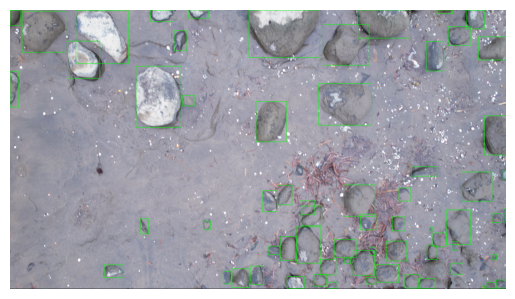

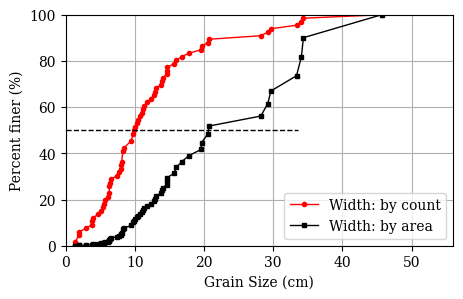

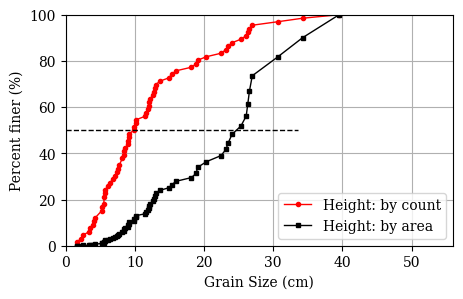

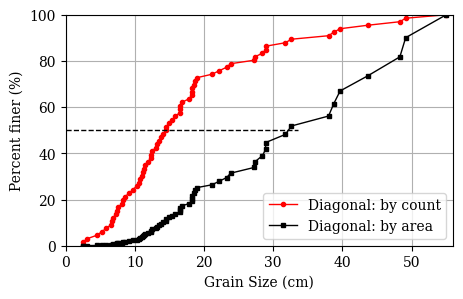

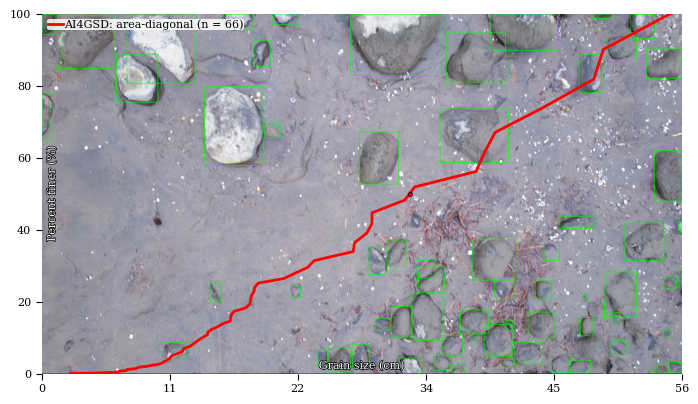

2/2: DJI_0113_4000.png, resolution 0.73 mm/px (100.00%), 16.00 s
Detected 3056 rocks, diagonal and count based D10, D50, D60, and D84 are: 3.36, 4.54, 4.86, and 6.26 cm
Detected 3056 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.86, 5.86, 6.69, and 11.54 cm


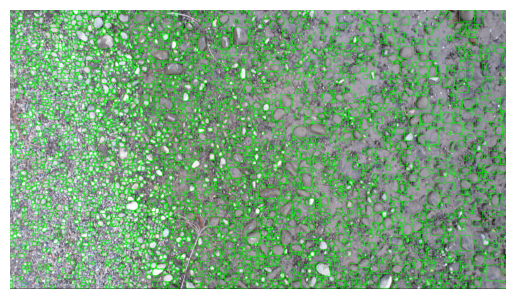

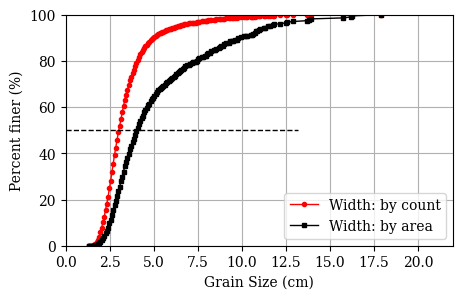

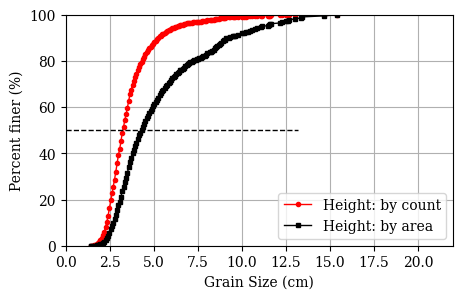

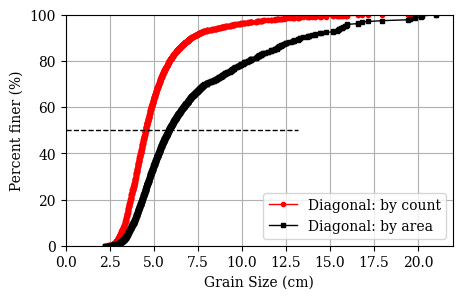

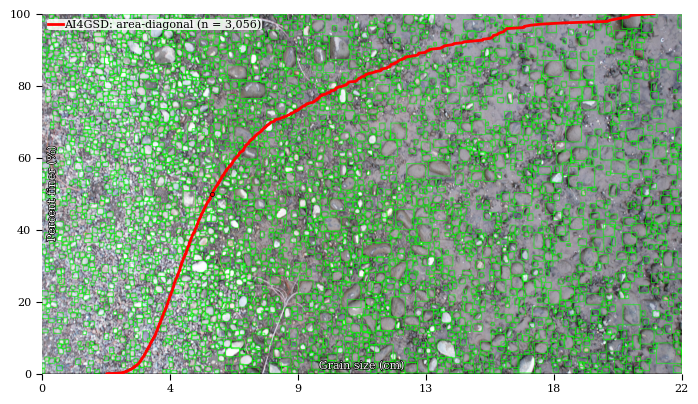

Output folder summary data to: /content/drive/MyDrive/AI4GSD/Demo_Data/20241130_YC_DroneVideoFieldTest/grains_predicts/20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35/Statistics_V3_20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35.csv
Total number of grains: 3122, number of grains per photo: 1561.00
Total time: 33.38 s, time per photo 16.69 s

Output all summary data to: /content/drive/MyDrive/AI4GSD/Demo_Data/20241130_YC_DroneVideoFieldTest/Statistics_V3_20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35.csv
Total execution time: 33.41 s


In [31]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.ModelName = 'YOLO11m.1280.20250322'
PP.OverWriteAll = True
PP.YOLOSave = False
PP.SaveOverlayLabel = True
PP.PrintOnScreen = True
PP.OverlayFontSize = 4
PP.OverlayLegendFontSize = 4
PP.OverlayGSDTickLineWidth = 4
gsd = AI4GSD.Photo2GSD(PP)

### 7. Applying quality control

In [32]:
gsdqc, stqc = AI4GSD.qualityControl(PhotoDir)


Quality control summary for 20241130_YC_DroneVideoFieldTest:
1/1: DJI_0113.MOV, time 240.2 s, area 14.8 m2, valid area 9.0 m2 (60.8%), frame 2, valid frame 1 (50.0%)
1/1: ***, grain number 3122, number per image 1561.0; efficiency 0.1 m2/s, 13.0 grains/s


### 8. Data visualization

#### Metadata and pixel sizes for all images

In [33]:
print(scales.head(10).T.to_string())

                                                                             0                                1
Name                                                         DJI_0113_2000.png                DJI_0113_4000.png
Folder                                         20241130_YC_DroneVideoFieldTest  20241130_YC_DroneVideoFieldTest
Scale_source                                                               log                              log
L1_px1_pixel                                                           -9999.0                          -9999.0
L1_py1_pixel                                                           -9999.0                          -9999.0
L1_px2_pixel                                                           -9999.0                          -9999.0
L1_py2_pixel                                                           -9999.0                          -9999.0
L2_px1_pixel                                                           -9999.0                          

#### Grain size data before quality control

In [34]:
print(gsd.head(10).T.to_string())

                                                                                                      0                                                         1
Name                                                                                  DJI_0113_2000.png                                         DJI_0113_4000.png
Folder                                                                  20241130_YC_DroneVideoFieldTest                           20241130_YC_DroneVideoFieldTest
Save_folder                                    20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35  20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35
Model_ID                                                                          YOLO11m.1280.20250322                                     YOLO11m.1280.20250322
Scale_source                                                                                        log                                                       log
L1_px1_pixel                

#### Grain size data after quality control

In [35]:
print(gsdqc.head(10).T.to_string())

                                                                                                      0
Name                                                                                  DJI_0113_4000.png
Folder                                                                  20241130_YC_DroneVideoFieldTest
Save_folder                                    20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35
Model_ID                                                                          YOLO11m.1280.20250322
Scale_source                                                                                        log
L1_px1_pixel                                                                                    -9999.0
L1_py1_pixel                                                                                    -9999.0
L1_px2_pixel                                                                                    -9999.0
L1_py2_pixel                                                    

#### Summary for each video

In [36]:
print(stqc.head(10).T.to_string())

                                                            0
Folder                        20241130_YC_DroneVideoFieldTest
Data_type                                                 0.0
Video_ID                                                  0.0
Video_name                                              113.0
Frame_rate_fps                                      23.976024
Width_px                                               5472.0
Height_px                                              3078.0
Dimension_megapixel                                 16.842816
Duration_s                                         240.198292
Grain_number_qc0                                       3122.0
Area_qc0_m2                                         14.765748
Area_qc2_m2                                          8.975421
Area_ratio_qc2                                       0.607854
Total_frame                                               2.0
Frame_qc0                                                 2.0
Frame_qc